# Delay aliasing: identical zero-lag correlation, different timing — 2026-10-20

Builds and tests the constructed example on which the SPI–SPI introduction rests ([`drafts/introduction_rewrite.md`](../../../../drafts/introduction_rewrite.md), paragraph 4 and "Points to formalise next", item 1). Two families of Gaussian MTS on the same $M$ channels have the same zero-lag correlation matrix entry for entry. Family A is synchronous; family B delays channel $j$ by $\tau_j$, so the delays differ from pair to pair. Every function of the zero-lag matrix is then identical across families, while $z$(zero-lag Pearson, lag-tolerant similarity) separates them and falls as the delays spread.

SPIs come from a five-SPI pyspi subset ([`spis/delay_alias.yaml`](../spis/delay_alias.yaml)) at the installed pyspi computation version; the full catalogue is not run. The generator is `mtsspi.generators.generate_delay_aliased_mts`; helpers and the figure are in [`delay_alias.py`](../delay_alias.py).

**Construction.** $X = sL^\top$ mixes $M$ independent unit-variance AR(1) sources with coefficient $a$, so $\mathrm{Cov}(X_j(t),X_k(t+h)) = \Sigma^*_{jk}\rho(h)$ with $\rho(h)=a^{|h|}$ and $LL^\top=\Sigma^*$. Delaying channel $j$ by $\tau_j$ gives zero-lag correlation $\Sigma^*\circ R$, $R_{jk}=\rho(\tau_j-\tau_k)$, and lag-tolerant similarity $\max_h \Sigma^*_{jk}\rho(h+\tau_j-\tau_k) = \Sigma^*_{jk}$. Setting $\Sigma^*=\Sigma\oslash R$ reproduces a target $\Sigma$ exactly, provided $\Sigma\oslash R$ is positive semidefinite (PSD).

$R$ is PSD (a Gram matrix of one stationary process), but $1\oslash R$ is not: its $2\times2$ minors are $1-\rho^{-2}<0$. Feasibility therefore has to come from the target. Section 2 shows that for a generic target it fails at small delay ranges. The generator uses a target built from delays, $\Sigma=\Sigma_0\circ R(\tau^{\max})$, with a one-factor $\Sigma_0$ (loadings $\lambda_j\sim U(0.6,0.8)$) and integer channel positions $\tau^{\max}_j$ spanning `max_lag_range`. A delay vector $\tau=\lfloor c\,\tau^{\max}+\tfrac12\rfloor$, $0\le c\le1$, and its complement $w=\tau^{\max}-\tau$ are both non-decreasing in $\tau^{\max}$. Hence $|\Delta\tau^{\max}|=|\Delta\tau|+|\Delta w|$, and $\Sigma\oslash R(\tau)=\Sigma_0\circ R(w)$. This is positive definite by the Schur product theorem, with $\lambda_{\min}\ge1-\max_j\lambda_j^2$, so every delay range up to `max_lag_range` reproduces the same $\Sigma$. The additive split needs $\rho(x+y)=\rho(x)\rho(y)$, i.e. exponential $\rho$. With continuous delays it extends to powered-exponential $\rho$ (inferred, not simulated). Physically, family B at the largest range is a nearly homogeneous common drive reaching channels at position-dependent times; family A has the same zero-lag structure from heterogeneous synchronous coupling.

In [1]:
from pathlib import Path
import sys, json, time, logging, warnings
ROOT = Path.cwd().resolve()
while not (ROOT / 'src').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
for p in (ROOT, ROOT / 'src'):  # this checkout's mtsspi, not another editable install
    if str(p) not in sys.path: sys.path.insert(0, str(p))
warnings.filterwarnings('ignore'); logging.disable(logging.WARNING)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pyspi, mtsspi
from research.cases.delay_alias import delay_alias as da
assert Path(mtsspi.__file__).is_relative_to(ROOT / 'src')
da.style(); pd.set_option('display.precision', 3)

P = dict(M=20, T=5_000, max_lag_range=15, ar1_a=0.9, loading_low=0.6, loading_high=0.8, structure_seed=0)
LAGS, N_REP = [0, 3, 6, 9, 12, 15], 20
ELL = -1 / np.log(P['ar1_a'])
OUT = ROOT / 'results/cases/delay-alias-261020'
print(f"pyspi {pyspi.COMPUTATION_VERSION}; correlation time {ELL:.2f} samples; "
      f"{len(LAGS)} delay ranges x {N_REP} recordings, M={P['M']}, T={P['T']}")

pyspi 3.0.0.r9; correlation time 9.49 samples; 6 delay ranges x 20 recordings, M=20, T=5000


## 1. Population checks

For every integer delay range: exactness of $\Sigma^*\circ R=\Sigma$, the PSD margin of $\Sigma^*$, and the population $z$ of an ideal lag-tolerant similarity, $\mathrm{corr}_{j<k}(\Sigma_{jk},\Sigma^*_{jk})$.

In [2]:
rows = []
for s in range(P['max_lag_range'] + 1):
    it = da.population(P, s)
    R = da.ar1_lag_attenuation(it.lags, P['ar1_a'])
    rows.append(dict(delay_range=s, sd_tau=it.lags.std(), identity_error=np.abs(it.intrinsic_corr * R - it.zero_lag_corr).max(),
                     lambda_min=np.linalg.eigvalsh(it.intrinsic_corr)[0], z_population=da.z(it.zero_lag_corr, it.intrinsic_corr),
                     mean_zero_lag=da.profile(it.zero_lag_corr).mean(), mean_intrinsic=da.profile(it.intrinsic_corr).mean()))
pop = pd.DataFrame(rows).set_index('delay_range')
assert (pop.identity_error < 1e-12).all() and (pop.lambda_min > 0).all() and (np.diff(pop.z_population) < 0).all()
Z_POP = pop.z_population.to_dict()
S = da.population(P, 0).zero_lag_corr
print(f"target zero-lag entries {da.profile(S).min():.3f}-{da.profile(S).max():.3f}; lambda_min(S0) bound {1 - 0.8**2:.2f}")
pop

target zero-lag entries 0.102-0.547; lambda_min(S0) bound 0.36


,sd_tau,identity_error,lambda_min,z_population,mean_zero_lag,mean_intrinsic
delay_range,,,,,,
0,0.000,0.000e+00,0.438,1.000,0.298,0.298
1,0.500,5.551e-17,0.397,0.991,0.298,0.312
2,0.707,5.551e-17,0.402,0.990,0.298,0.318
3,1.025,5.551e-17,0.397,0.987,0.298,0.330
4,1.140,5.551e-17,0.438,0.985,0.298,0.334
5,1.500,5.551e-17,0.397,0.978,0.298,0.347
6,1.844,5.551e-17,0.402,0.970,0.298,0.360
7,2.202,5.551e-17,0.397,0.960,0.298,0.375
8,2.324,5.551e-17,0.402,0.948,0.298,0.381


## 2. Feasibility of the generic construction

Here the target is the one-factor $\Sigma_0$ alone, not built from delays, with delays $s\cdot\mathrm{linspace}(0,1,M)$. The table reports the largest PSD-feasible delay range $s^*$ in correlation times $\ell=-1/\ln a$ (independent of $a$ for exponential $\rho$), and the population $z$ at $s^*$. Values are medians over 20 loading draws, with 5–95% ranges. An equicorrelated two-group case shows why feasibility shrinks with $M$ and strength: groups of $n$ channels with correlation $c$ and delays $0$ and $\Delta$ need $\rho(\Delta)^{-1}-1<(1-c)/(nc)$.

In [3]:
rows = []
for M in (10, 20, 40):
    for lo, hi in ((0.2, 0.4), (0.4, 0.6), (0.6, 0.8)):
        f = da.generic_feasibility(M, lo, hi, seeds=range(20))
        q = lambda c: f"{f[c].median():.2f} [{f[c].quantile(.05):.2f}, {f[c].quantile(.95):.2f}]"
        rows.append({'M': M, 'loadings': f'{lo}-{hi}', 'mean target r': round(f.target_mean.mean(), 3),
                     's*/ell': q('range_over_ell'), 'z at s*': q('z_population')})
feas = pd.DataFrame(rows)
feas

,M,loadings,mean target r,s*/ell,z at s*
0,10,0.2-0.4,0.091,"1.71 [1.51, 1.94]","0.54 [0.19, 0.71]"
1,10,0.4-0.6,0.252,"0.83 [0.73, 0.94]","0.63 [0.28, 0.79]"
2,10,0.6-0.8,0.493,"0.35 [0.30, 0.41]","0.81 [0.53, 0.90]"
3,20,0.2-0.4,0.092,"1.22 [1.11, 1.36]","0.61 [0.53, 0.69]"
4,20,0.4-0.6,0.254,"0.52 [0.47, 0.57]","0.75 [0.70, 0.82]"
5,20,0.6-0.8,0.495,"0.20 [0.18, 0.23]","0.91 [0.88, 0.94]"
6,40,0.2-0.4,0.092,"0.81 [0.75, 0.87]","0.78 [0.74, 0.82]"
7,40,0.4-0.6,0.253,"0.31 [0.28, 0.33]","0.90 [0.89, 0.92]"
8,40,0.6-0.8,0.494,"0.11 [0.10, 0.12]","0.97 [0.97, 0.98]"


## 3. Recordings and SPIs

Family A is delay range 0; family B is every positive range. All share the target $\Sigma$ above (`structure_seed=0`), and each recording has independent source noise. Each recording runs the pyspi subset: zero-lag Pearson (`cov_EmpiricalCovariance` on z-scored data), Spearman, maximum cross-correlation over $\pm T/4$ lags, minimum cross-Euclidean distance over $\pm30$ lags (negated to a similarity), and mean multitaper coherence magnitude. `xcorr_max_sig-True` and `cohmag` are catalogue (p90) SPIs; the catalogue's cross distance uses $\tau=1$, too short for these delays.

In [4]:
t0 = time.time()
frame, mats = da.measure(P, LAGS, N_REP)
OUT.mkdir(parents=True, exist_ok=True)
frame.to_csv(OUT / 'z_by_recording.csv', index=False)
print(f"{len(LAGS) * N_REP} recordings in {time.time() - t0:.0f} s")
ZL, XC = 0, 1 + list(da.PAIRED).index('xcorr_max_sig-True')
A, B = mats[0], mats[max(LAGS)]

120 recordings in 23 s


## 4. The zero-lag matrices agree up to sampling error

Population matrices are identical by construction (section 1). Finite-sample matrices are compared in three ways. The first is each recording's entry-wise error against $\Sigma$. The second compares Frobenius distances between recordings of different families with those between recordings of the same family. The third is the replicate-mean matrix of each family. The last block repeats the error for other $T$ using `np.corrcoef` only.

In [5]:
def errs(stack):
    e = np.array([da.profile(C - S) for C in stack[:, ZL]])
    return dict(rms=np.sqrt((e**2).mean()), mean_abs=np.abs(e).mean(), max_abs_per_rec=np.abs(e).max(1).mean(),
                replicate_mean_max_abs=np.abs(e.mean(0)).max())
err = pd.DataFrame({'A (sync)': errs(A), f'B (range {max(LAGS)})': errs(B)}).T
def fro(X, Y, same):
    return [np.linalg.norm(da.profile(X[i, ZL] - Y[j, ZL])) for i in range(N_REP) for j in range(N_REP) if not (same and i >= j)]
dist = {'A-A': fro(A, A, True), 'B-B': fro(B, B, True), 'A-B': fro(A, B, False)}
display(err)
print('Frobenius distance between upper triangles (median [5%, 95%]):')
for k, v in dist.items(): print(f'  {k}: {np.median(v):.3f} [{np.quantile(v, .05):.3f}, {np.quantile(v, .95):.3f}]')
sd_ratio = np.array([da.profile(B[:, ZL].std(0))]) / np.array([da.profile(A[:, ZL].std(0))])
print(f'per-entry replicate SD, B/A: median {np.median(sd_ratio):.2f} [{np.quantile(sd_ratio, .05):.2f}, {np.quantile(sd_ratio, .95):.2f}]')

rows = []
for T in (2_000, 5_000, 20_000, 50_000):
    for fam, s in (('A', 0), ('B', max(LAGS))):
        e = [da.profile(np.corrcoef(da.generate_delay_aliased_mts(**{**P, 'T': T}, lag_range=s, rng=da.recording_rng(99, s, r)).T) - S)
             for r in range(10)]
        rows.append(dict(T=T, family=fam, rms=np.sqrt(np.mean(np.square(e))), max_abs=np.mean(np.abs(e).max(1))))
by_T = pd.DataFrame(rows).pivot(index='T', columns='family')
by_T

,rms,mean_abs,max_abs_per_rec,replicate_mean_max_abs
A (sync),0.039,0.031,0.112,0.023
B (range 15),0.038,0.030,0.109,0.019


Frobenius distance between upper triangles (median [5%, 95%]):
  A-A: 0.735 [0.612, 0.929]
  B-B: 0.721 [0.591, 1.011]
  A-B: 0.718 [0.601, 0.965]
per-entry replicate SD, B/A: median 0.99 [0.65, 1.42]


rms        max_abs       
family      A      B       A      B
T                                  
2000    0.063  0.058   0.190  0.165
5000    0.039  0.036   0.118  0.104
20000   0.019  0.019   0.054  0.057
50000   0.012  0.011   0.034  0.032

## 5. Functions of the zero-lag matrix do not separate the families; $z$ does

The table compares A with B at the largest delay range, using 20 recordings each. AUC is $P(B>A)$ with a two-sided Mann–Whitney $p$. Under the null, 20 vs 20 gives AUC within about $0.5\pm0.18$ (95%). The zero-lag summaries are the mean correlation, the leading, second and smallest eigenvalues, and the mean Onnela weighted clustering coefficient. For each lag-tolerant SPI, the table gives $z$ against zero-lag Pearson and its profile mean (a per-statistic summary).

In [6]:
summ = lambda stack: pd.DataFrame([da.zero_lag_summaries(C) for C in stack[:, ZL]])
sa, sb = summ(A), summ(B)
rows = {k: da.separation(sa[k], sb[k]) for k in sa}
fa, fb = frame[frame.lag_range == 0], frame[frame.lag_range == max(LAGS)]
for spi in da.PAIRED:
    rows[f'z: {da.LABELS[spi]}'] = da.separation(fa[fa.spi == spi].z, fb[fb.spi == spi].z)
for spi in ['xcorr_max_sig-True', 'cohmag_multitaper_mean_fs-1_fmin-0_fmax-0-5']:
    rows[f'mean: {da.LABELS[spi]}'] = da.separation(fa[fa.spi == spi]['mean'], fb[fb.spi == spi]['mean'])
sep = pd.DataFrame(rows).T
sep

,A mean,A sd,B mean,B sd,AUC,p
mean r,0.297,1.673e-02,0.298,1.996e-02,0.515,8.817e-01
lambda_1,6.797,3.175e-01,6.800,3.726e-01,0.505,9.676e-01
lambda_2,2.287,1.070e-01,2.274,1.079e-01,0.472,7.764e-01
lambda_M,0.359,1.645e-02,0.368,1.970e-02,0.623,1.895e-01
weighted clustering,0.499,2.802e-02,0.499,2.990e-02,0.500,1.000e+00
z: max cross-correlation,0.997,2.634e-03,0.471,2.839e-02,0.000,6.796e-08
z: $-$min cross-distance,0.999,3.385e-04,0.477,2.650e-02,0.000,6.796e-08
z: coherence magnitude,0.935,6.043e-03,0.419,3.878e-02,0.000,6.796e-08
z: Spearman (zero-lag control),0.997,4.599e-04,0.997,4.693e-04,0.670,6.787e-02
mean: max cross-correlation,0.299,1.565e-02,0.494,1.511e-02,1.000,6.796e-08


## 6. $z$ against delay range

Points are single recordings and the solid line is the replicate median. The dashed line is the population $z$ of an ideal lag-tolerant similarity (section 1). The Spearman row is a zero-lag control. For Gaussian data the single-time joint law is $N(0,\Sigma)$ in both families, so every contemporaneous statistic has the same population value in both.

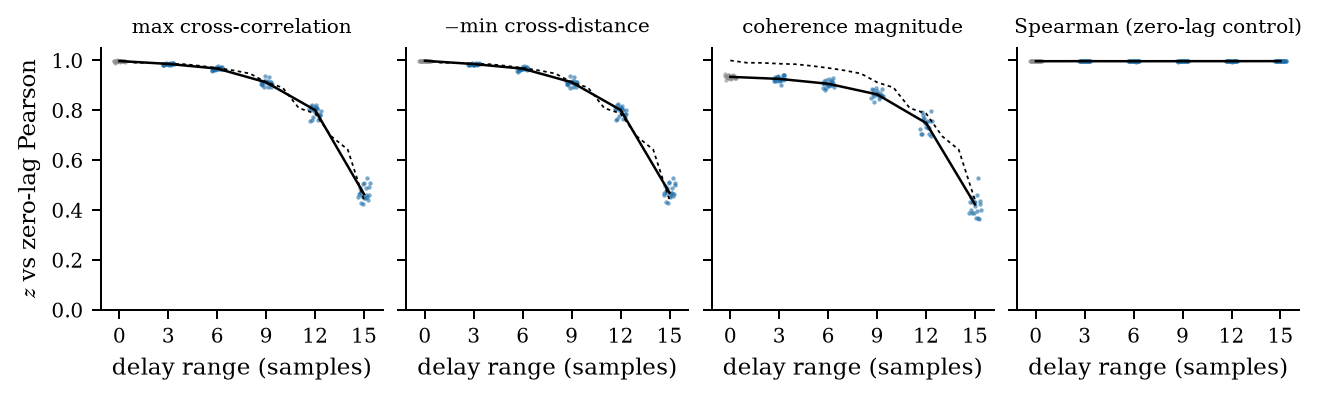

lag_range,0,3,6,9,12,15
spi,,,,,,
coherence magnitude,0.934,0.926,0.907,0.864,0.749,0.423
Spearman (zero-lag control),0.997,0.997,0.997,0.997,0.997,0.997
max cross-correlation,0.998,0.986,0.968,0.912,0.801,0.464
$-$min cross-distance,0.999,0.986,0.967,0.913,0.801,0.470


In [7]:
fig, axes = plt.subplots(1, 4, figsize=(7.2, 2.1), sharey=True, constrained_layout=True)
for ax, spi in zip(axes, da.PAIRED):
    sub = frame[frame.spi == spi]
    for lag, grp in sub.groupby('lag_range'):
        ax.scatter(np.full(len(grp), lag) + np.linspace(-.35, .35, len(grp)), grp.z, s=3, lw=0, alpha=.6,
                   color=da.COLORS['A'] if lag == 0 else da.COLORS['B'])
    ax.plot(LAGS, sub.groupby('lag_range').z.median(), color='k', lw=1)
    if spi != 'spearmanr':  # ideal lag-tolerant population z; not the control's estimand
        ax.plot(pop.index, pop.z_population, color='k', lw=.7, ls=(0, (2, 2)))
    ax.set(title=da.LABELS[spi], xlabel='delay range (samples)', ylim=(0, 1.05), xticks=LAGS)
    ax.title.set_fontsize(8)
axes[0].set_ylabel('$z$ vs zero-lag Pearson')
da.save(fig, OUT, 'z_vs_delay_range'); plt.show()
frame[frame.spi != da.ZERO_LAG].groupby(['spi', 'lag_range']).z.median().unstack().rename(index=da.LABELS)

## 7. The delayed lag-tolerant profile estimates $\Sigma\oslash R$

The maximum cross-correlation should estimate $\Sigma^*$, which equals $\Sigma\oslash R$ in B and $\Sigma$ in A. The table reports RMS errors against that estimand and against the other family's estimand.

In [8]:
Sstar = da.population(P, max(LAGS)).intrinsic_corr
rms = lambda stack, M: np.sqrt(np.mean([np.square(da.profile(X - M)) for X in stack[:, XC]]))
pd.DataFrame({'vs Sigma': [rms(A, S), rms(B, S)], 'vs Sigma / R': [rms(A, Sstar), rms(B, Sstar)]},
             index=['A max xcorr', 'B max xcorr'])

,vs Sigma,vs Sigma / R
A max xcorr,0.037,0.221
B max xcorr,0.222,0.032


## 8. Other target structures

The loadings are redrawn with structure seeds 1–5, using five recordings each at delay range 0 and at the largest range.

In [9]:
rows = []
for seed in range(1, 6):
    Ps = {**P, 'structure_seed': seed}
    f, _ = da.measure(Ps, [0, max(LAGS)], 5)
    f = f[f.spi == 'xcorr_max_sig-True']
    it = da.population(Ps, max(LAGS))
    rows.append(dict(seed=seed, z_A=f[f.lag_range == 0].z.median(), z_B=f[f.lag_range == max(LAGS)].z.median(),
                     z_B_sd=f[f.lag_range == max(LAGS)].z.std(), z_population_B=da.z(it.zero_lag_corr, it.intrinsic_corr)))
pd.DataFrame(rows).set_index('seed')

,z_A,z_B,z_B_sd,z_population_B
seed,,,,
1,0.998,0.423,0.056,0.325
2,0.996,0.334,0.053,0.302
3,0.997,0.460,0.060,0.323
4,0.998,0.296,0.065,0.277
5,0.999,0.387,0.038,0.321


## 9. Fig. 1 candidate

One recording per family (replicate 0). The x-axis is each channel pair's zero-lag correlation and the y-axis its maximum cross-correlation. The inset shows $z$ for every recording against delay range, with the population curve dashed.

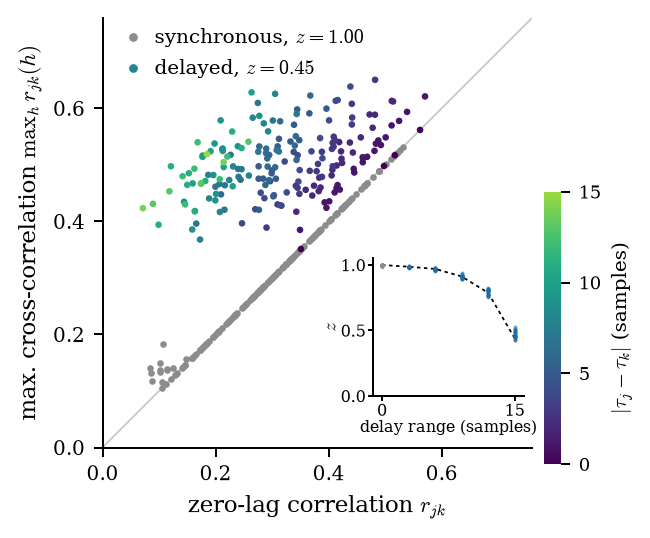

5163

In [10]:
fig = da.plot_fig1(mats, frame, P, max(LAGS), Z_POP)
da.save(fig, OUT, 'fig1_candidate'); plt.show()
summary = dict(params=P, lag_ranges=LAGS, n_rep=N_REP, pyspi=pyspi.COMPUTATION_VERSION,
               correlation_time=ELL, zero_lag_error=err.to_dict(), z_median=frame.groupby(['spi', 'lag_range']).z.median().unstack().to_dict(),
               separation=sep[['A mean', 'B mean', 'AUC', 'p']].to_dict(), population=pop[['lambda_min', 'z_population']].to_dict())
(OUT / 'summary.json').write_text(json.dumps(summary, indent=1, default=float))

## Summary

Numbers are from the run above: $M=20$, $T=5000$ (about 530 correlation times; $a=0.9$, $\ell=9.5$ samples), 20 recordings per delay range.

- **Exact match.** At every integer delay range 0–15 (up to $1.6\ell$), $\Sigma^*\circ R$ reproduces $\Sigma$ to $6\times10^{-17}$ and $\lambda_{\min}(\Sigma^*)\ge0.38$. Every function of the zero-lag matrix therefore has identical population values in both families. Because the single-time law is $N(0,\Sigma)$ in both, so does every contemporaneous statistic.
- **Finite sample.** The entry-wise RMS error against $\Sigma$ is 0.039 (A) and 0.038 (B), with a per-recording maximum of about 0.11. It scales as $T^{-1/2}$: 0.063 at $T=2000$, 0.019 at $20\,000$ and 0.012 at $50\,000$. Distances between families lie within the distances inside each family. Mean $r$, $\lambda_1$, $\lambda_2$, $\lambda_M$ and weighted clustering do not separate the families (AUC 0.47–0.62, $p\ge0.19$). Per-entry sampling SDs are similar (B/A median 0.99, 5–95% range 0.65–1.42; median 0.92 at $T=20\,000$). Bartlett's formula allows a difference, because the families' cross-correlation functions differ. The matrices agree in expectation; agreement in sampling distribution is not guaranteed.
- **$z$ separates.** For $z$(Pearson, max cross-correlation), A gives $0.997\pm0.003$ and B at range 15 gives $0.471\pm0.028$ (AUC 0; population 0.440). The −min cross-distance gives 0.477 and coherence magnitude 0.419. Coherence magnitude reaches only 0.935 in A, because multitaper magnitude bias compresses weak pairs. The Spearman control gives 0.997 in both families (AUC 0.67, $p=0.07$, within the 20-vs-20 null range). Median $z$ falls monotonically but convexly with delay range: 0.97 at 6, 0.91 at 9, 0.80 at 12 and 0.46 at 15. It tracks how much of the zero-lag structure the delays produce, not delay spread alone. B's max cross-correlation estimates $\Sigma\oslash R$ with RMS error 0.032.
- **Cost of $T=5000$.** Across six loading draws, $z_B$ is 0.30–0.47 against $z_A\ge0.996$, so separation is unaffected. But $z_B$ lies 0.02–0.14 above its population value (0.03 for the main target), against at most 0.04 at $T=20\,000$. A likely cause is that the estimation errors at lag 0 and at the peak lag are correlated for AR(1) data, which pulls $z$ towards 1 (inferred). In Fig. 1, the weakest synchronous pairs ($r\approx0.1$) sit slightly above the identity line, because the maximum over $\pm T/4$ lags picks up sampling noise.
- **Per-statistic means also separate the families** (mean max cross-correlation 0.299 vs 0.494, AUC 1), as the introduction concedes: B reads as stronger lag-tolerant coupling.
- **Feasible range.**
  - *Generic target, not built from delays.* The largest PSD-feasible delay range is $0.11$–$1.7\ell$ and shrinks with $M$ and target strength. At $M=20$ it is $1.22\ell$ at mean $r=0.09$, $0.52\ell$ at 0.25 and $0.20\ell$ at 0.49. Population $z$ at that limit is only 0.54–0.97. The proposed $\Sigma\oslash R$ construction is therefore workable only for weak coupling or small $M$. For the strong target at $M=20$, with $a=0.9$ and evenly spaced integer delays, it fails already at a 1-sample range.
  - *Structured target $\Sigma=\Sigma_0\circ R(\tau^{\max})$.* Every range up to `max_lag_range` is feasible by construction, here up to $1.6\ell$.
  - *Always-feasible alternative.* Fix $\Sigma^*$ and set $\Sigma=\Sigma^*\circ R$ at each spread. The families match exactly at each spread, but $\Sigma$ changes with spread.
- **Limits.**
  - A zero-lag matrix admits delays $\tau$ only if $\Sigma=\Sigma^*\circ R(\tau)$ for some correlation matrix $\Sigma^*$. Large delay heterogeneity at a fixed strong $\Sigma$ therefore needs structure in $\Sigma$ that is consistent with the delays. The synchronous family can realise any $\Sigma$, so the aliasing claim stands, but it does not hold for an arbitrary pair $(\Sigma,\tau)$.
  - The construction assumes a separable, Gaussian, broadband AR(1) process. An oscillatory $\rho$ changes sign, so $\Sigma\oslash R$ is undefined beyond its first zero. The narrowband case behind the spectral objection is not covered.
  - The cross-correlation uses pyspi's $\pm T/4$ window. The cross-distance uses a non-catalogue $\tau=30$.